# LaTeX drawing and a trainable CNN–quantum model

This CPU example preserves the existing text and Matplotlib workflows, exports
editable LaTeX, and displays figures directly in Notebook output cells.
The hybrid drawing explicitly describes each classical layer and batch-free tensor
shape. The declarations are checked against actual model outputs below; arbitrary
PyTorch models are not automatically traced.

Prerequisites: install this FlagQuantum checkout and Jupyter/IPython. Source export
needs no additional tools. To display the LaTeX figure, install **Tectonic** (or
TeX Live) and **Poppler** (`pdftocairo` for SVG, or `pdftoppm` for PNG) on the
Notebook kernel's PATH. For example, macOS users can run
`brew install tectonic poppler`; TeX Live plus Poppler also works on Linux.
Tectonic may download standard TeX resources on first use. FlagQuantum itself
never downloads or installs rendering executables.

In [1]:
from pathlib import Path

import torch
from torch import nn
from IPython.display import display

import flagquantum as fq
from flagquantum.drawer import ClassicalLayer, draw_hybrid

torch.manual_seed(7)
torch.set_num_threads(1)

## Existing draw behavior

The default still returns terminal text. Matplotlib still returns `(figure, axes)`;
its optional dependency is installed with `pip install "flagquantum[viz]"`.

0: ───H───╭●─┤
1: ───────╰X─┤


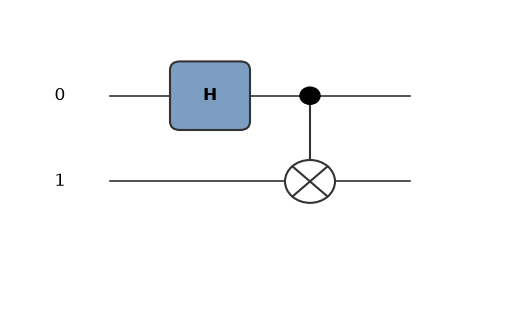

In [2]:
bell = fq.Circuit(2).h(0).cx(0, 1)
print(bell.draw())

from matplotlib import pyplot as plt

mpl_figure, axes = bell.draw(format="mpl")
display(mpl_figure)
plt.close(mpl_figure)

## Editable source and inline rendering

`format="latex"` returns a lazy `LatexFigure`. Reading `.source` or writing `.tex`
does not compile anything. Returning the object as the final expression of a cell
invokes the Notebook MIME protocol: SVG when `pdftocairo` is available, otherwise
PNG. `display=True` explicitly displays the same object.

In [3]:
symbolic = fq.Circuit(3)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"x_{qubit}"))
symbolic.cx(0, 1).cx(1, 2)
for qubit in range(3):
    symbolic.ry(qubit, fq.Parameter(f"theta_{qubit}"))

circuit_figure = symbolic.draw(format="latex")
print(circuit_figure.source)

\documentclass[border=12pt]{standalone}
\usepackage{flaghybrid}
\begin{document}
\begin{tikzpicture}
\begin{yquant}
qubit {$q_{\idx}$} q[3];
box {$R_y(x_{0})$} q[0];
box {$R_y(x_{1})$} q[1];
box {$R_y(x_{2})$} q[2];
cnot q[1] | q[0];
cnot q[2] | q[1];
box {$R_y(\theta_{0})$} q[0];
box {$R_y(\theta_{1})$} q[1];
box {$R_y(\theta_{2})$} q[2];
\end{yquant}
\end{tikzpicture}
\end{document}



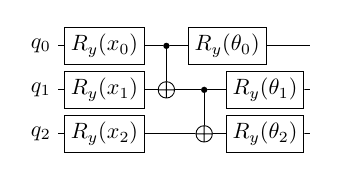

In [4]:
circuit_figure

## A real differentiable hybrid model

A small CNN maps a 1×8×8 input to three angle features. Three trainable quantum
rotations follow the entangling gates. The head maps the three Z expectations to
two class logits. One synthetic CPU training step demonstrates gradients through
all three components; it is not an accuracy or performance benchmark.

In [5]:
class HybridCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 3, kernel_size=3, padding=1),
            nn.Tanh(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.theta = nn.Parameter(0.1 * torch.randn(3))
        self.head = nn.Linear(3, 2)

    def quantum_features(self, features: torch.Tensor) -> torch.Tensor:
        circuit = fq.Circuit(3)
        for qubit in range(3):
            circuit.ry(qubit, features[qubit])
        circuit.cx(0, 1).cx(1, 2)
        for qubit in range(3):
            circuit.ry(qubit, self.theta[qubit])
        return torch.stack([
            circuit.expectation_z(qubit).reshape(()) for qubit in range(3)
        ])

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.encoder(images)
        quantum = torch.stack([self.quantum_features(row) for row in features])
        return self.head(quantum)


model = HybridCNN()
images = torch.randn(4, 1, 8, 8)
labels = torch.tensor([0, 1, 0, 1])
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
optimizer.zero_grad()
loss = nn.functional.cross_entropy(model(images), labels)
loss.backward()

for name, parameter in (
    ("CNN", model.encoder[0].weight),
    ("quantum", model.theta),
    ("head", model.head.weight),
):
    assert parameter.grad is not None
    assert torch.isfinite(parameter.grad).all()
    assert parameter.grad.abs().sum() > 0
    print(f"{name} gradient norm: {parameter.grad.norm().item():.6f}")

before = model.theta.detach().clone()
optimizer.step()
assert not torch.equal(before, model.theta.detach())
print(f"Synthetic training loss: {loss.detach().item():.6f}")

CNN gradient norm: 0.003033
quantum gradient norm: 0.001278
head gradient norm: 0.209511
Synthetic training loss: 0.707551


## Declare and verify the architecture

Each layer records input/output shapes without the batch dimension. The drawer
checks adjacent shapes and the readout/head boundary. We also run the actual
encoder and head below: a shape declaration alone cannot verify a Conv/Pool
operation formula. The symbolic gate sequence matches `quantum_features`.

Only Conv2d, the circuit parameters and Linear own trainable parameters. Tanh,
Pool and Flatten remain fixed transformations. Their input gradients still flow;
fixed transformations are not detached. Readout explicitly means the three Z
expectation values actually computed by the model.


Conv2d 3x3: (1, 8, 8) -> (3, 8, 8)
Tanh: (3, 8, 8) -> (3, 8, 8)
AdaptiveAvgPool2d: (3, 8, 8) -> (3, 1, 1)
Flatten: (3, 1, 1) -> (3,)


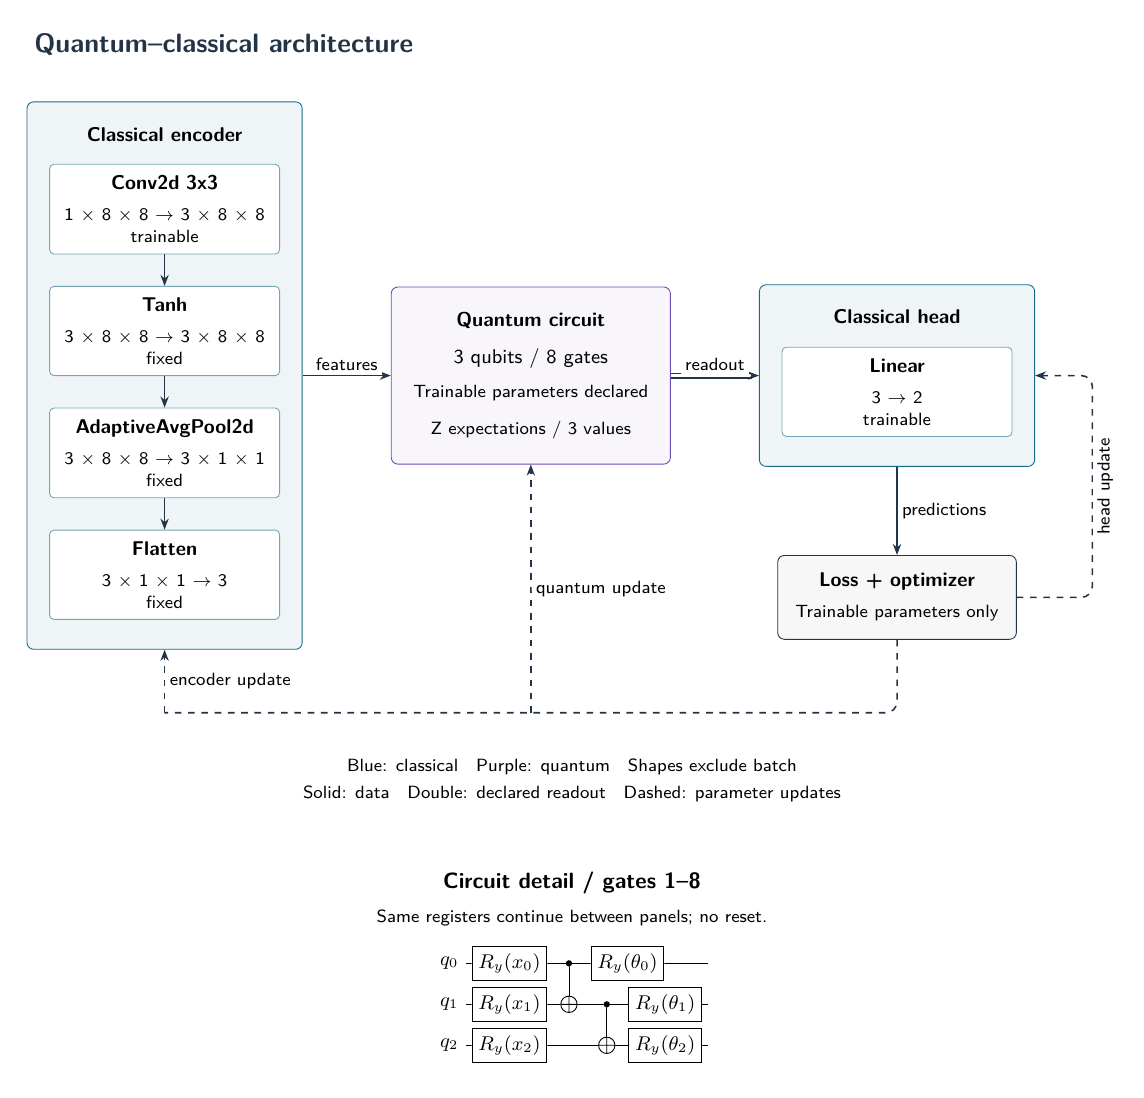

In [6]:
encoder_layers = (
    ClassicalLayer("Conv2d 3x3", (1, 8, 8), (3, 8, 8), trainable=True),
    ClassicalLayer("Tanh", (3, 8, 8), (3, 8, 8)),
    ClassicalLayer("AdaptiveAvgPool2d", (3, 8, 8), (3, 1, 1)),
    ClassicalLayer("Flatten", (3, 1, 1), (3,)),
)
head_layers = (ClassicalLayer("Linear", (3,), (2,), trainable=True),)

with torch.no_grad():
    value = images[:1]
    for module, layer in zip(model.encoder, encoder_layers, strict=True):
        assert any(p.requires_grad for p in module.parameters()) == layer.trainable
        assert tuple(value.shape[1:]) == layer.input_shape
        value = module(value)
        assert tuple(value.shape[1:]) == layer.output_shape
        print(f"{layer.label}: {layer.input_shape} -> {tuple(value.shape[1:])}")
    readout = torch.stack([model.quantum_features(row) for row in value])
    assert tuple(readout.shape[1:]) == head_layers[0].input_shape
    assert tuple(model.head(readout).shape[1:]) == head_layers[0].output_shape

hybrid_figure = draw_hybrid(
    symbolic, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=readout.shape[-1],
    training=True, quantum_view="detail",
)
hybrid_figure


## Save editable source and a portable project

The diagram keeps normal-size circuit detail below the architecture instead of
shrinking it into an inset. `.export_bundle()` includes the matching runtime and
component licenses. Saving after inline display reuses the figure's compilation.


In [7]:
output = Path("latex_exports")
output.mkdir(exist_ok=True)
hybrid_figure.save_source(output / "cnn-hybrid-detail.tex")
main_file = hybrid_figure.export_bundle(output / "overleaf")
hybrid_figure.save(output / "cnn-hybrid-detail.pdf")
hybrid_figure.save(output / "cnn-hybrid-detail.png")
print(f"Portable project: {main_file}")


Portable project: latex_exports/overleaf/figure.tex


## Freeze the encoder: verify gradients and show overview

This is an actual frozen copy of the trained model. The optimizer receives only
trainable parameters. The encoder receives no update arrow, while quantum and
head feedback remain. `overview` omits circuit detail for compact architecture
figures; it still validates the complete circuit before exporting source.


Frozen encoder: no gradients; quantum and head: finite nonzero gradients


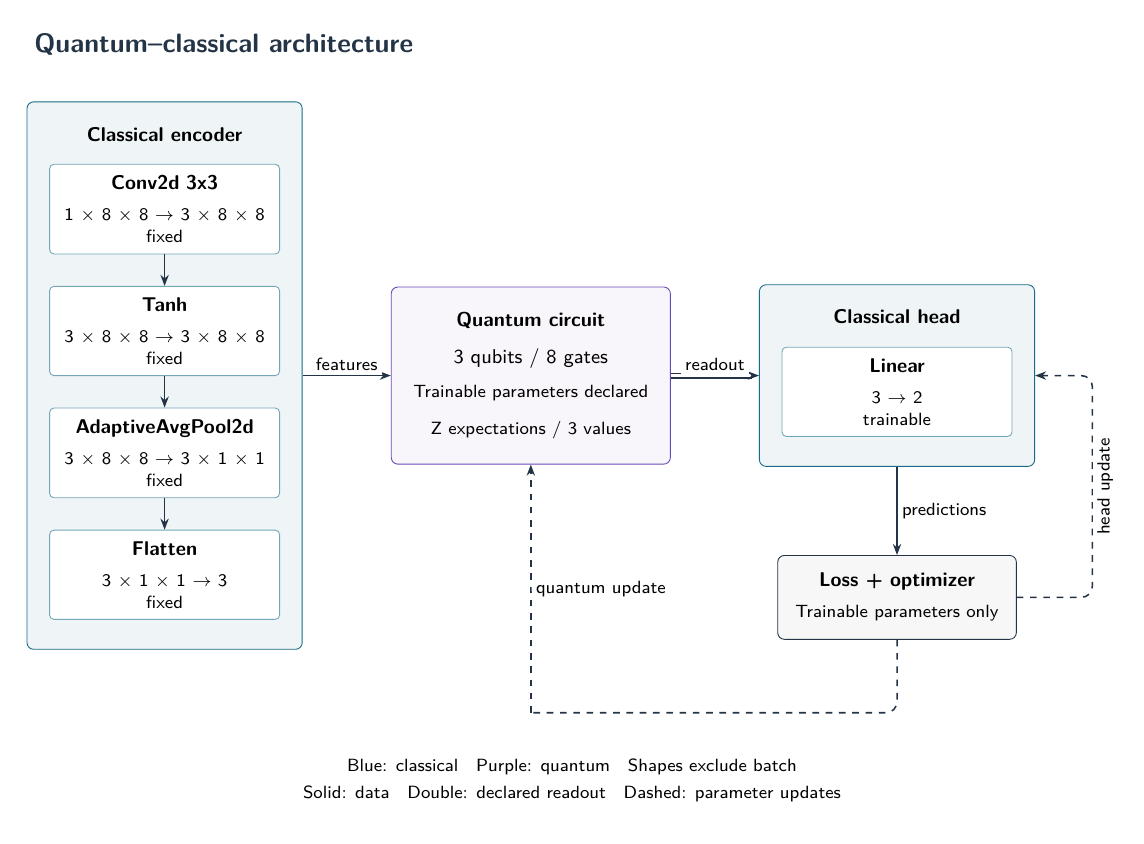

In [8]:
from copy import deepcopy

frozen_model = deepcopy(model)
frozen_model.encoder.requires_grad_(False)
frozen_optimizer = torch.optim.Adam(
    (parameter for parameter in frozen_model.parameters() if parameter.requires_grad),
    lr=0.01,
)
frozen_optimizer.zero_grad(set_to_none=True)
frozen_loss = nn.functional.cross_entropy(frozen_model(images), labels)
frozen_loss.backward()
assert all(parameter.grad is None for parameter in frozen_model.encoder.parameters())
assert frozen_model.theta.grad is not None
assert torch.isfinite(frozen_model.theta.grad).all()
assert frozen_model.theta.grad.norm() > 0
assert frozen_model.head.weight.grad is not None
assert torch.isfinite(frozen_model.head.weight.grad).all()
assert frozen_model.head.weight.grad.norm() > 0
frozen_optimizer.step()
print("Frozen encoder: no gradients; quantum and head: finite nonzero gradients")

overview = draw_hybrid(
    symbolic, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=3, training=True,
    encoder_trainable=False, quantum_view="overview",
)
assert "encoder update" not in overview.source
for extension in ("tex", "pdf", "png"):
    overview.save(output / f"cnn-hybrid-overview.{extension}")
overview


## Longer circuit: ordered continuation panels

This separate layout example has 24 rotations; it is not the trained circuit
above. Auto view uses a qubit/gate-count overview plus six-gate detail panels.
Panels continue the same registers, in order, without resets. Fonts retain their
natural size. Very large circuits can use overview alone and export circuit
source separately. The diagram does not infer an encoding or measurement.


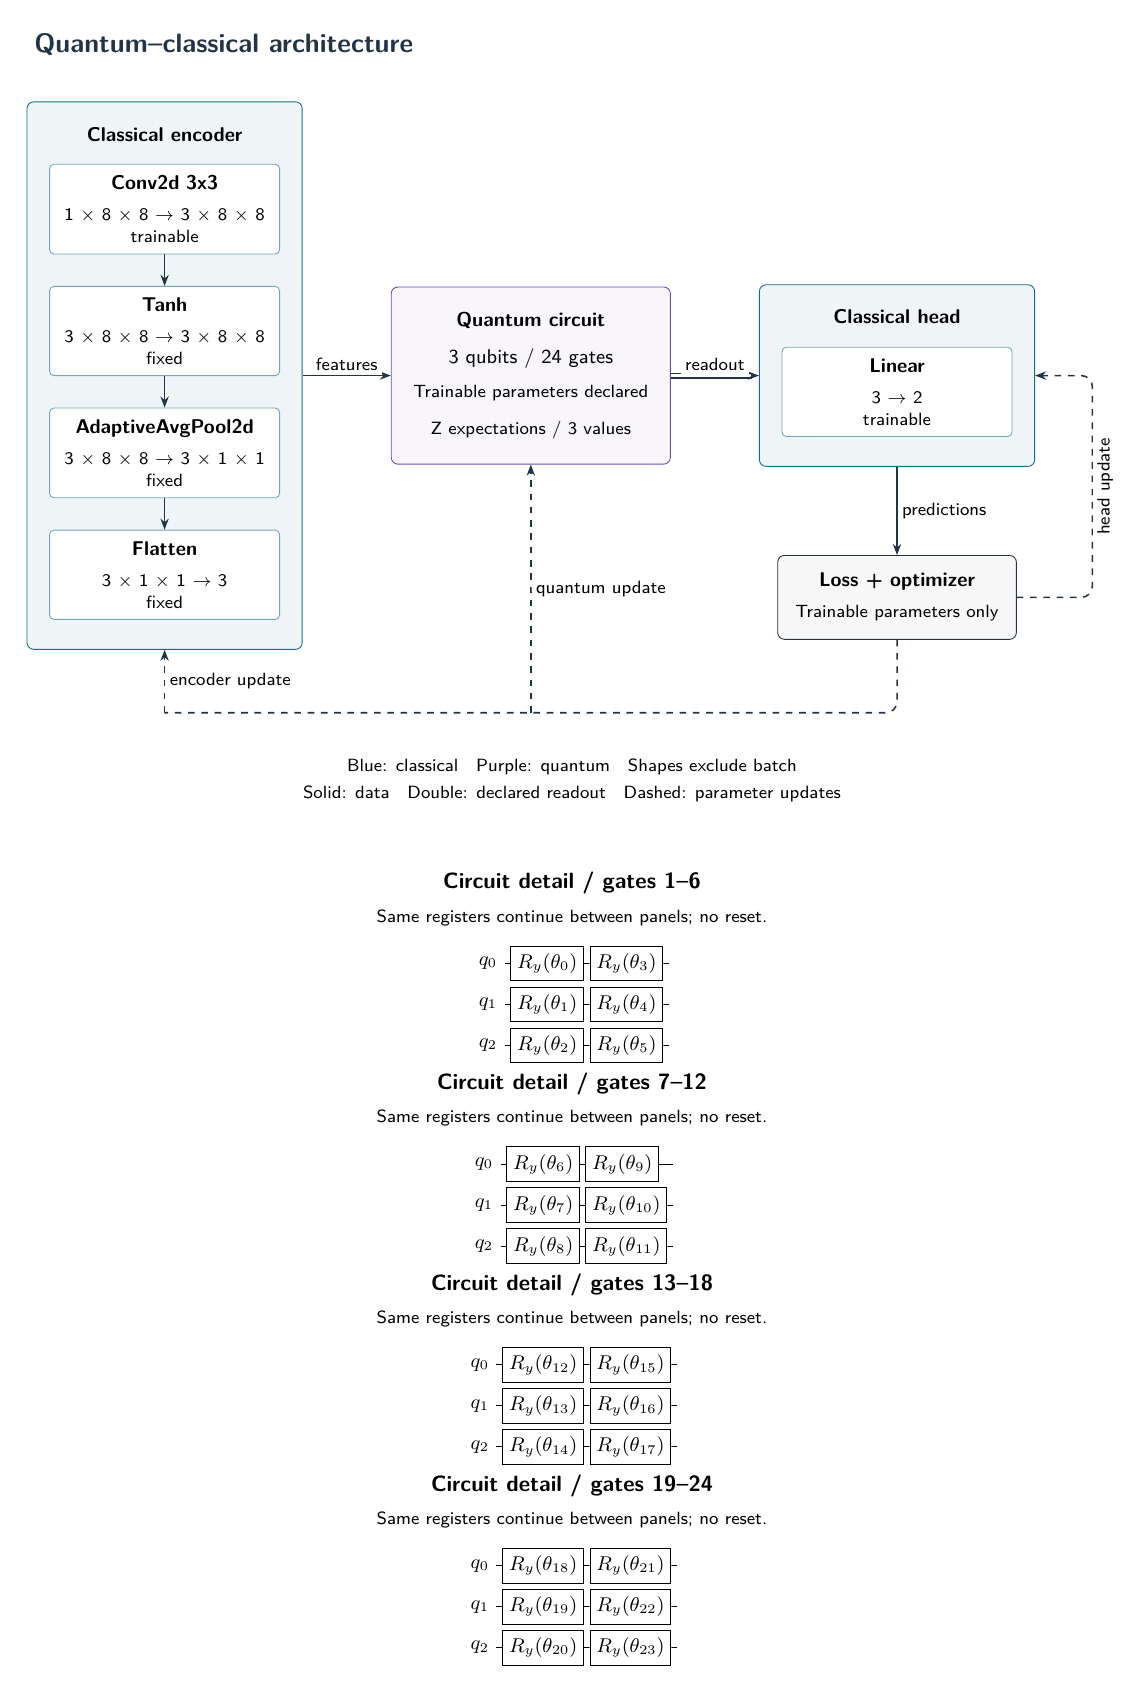

In [9]:
long_circuit = fq.Circuit(3)
for index in range(24):
    long_circuit.ry(index % 3, fq.Parameter(f"theta_{index}"))
long_figure = draw_hybrid(
    long_circuit, encoder=encoder_layers, head=head_layers,
    readout="Z expectations", readout_features=3,
    training=True, quantum_view="auto", gates_per_panel=6,
)
for extension in ("tex", "pdf", "png"):
    long_figure.save(output / f"long-circuit-hybrid.{extension}")
long_figure


## Support boundary

The drawer validates declared dimensions, not model operation formulas, encoder
mathematics, gradient correctness, arbitrary graph branches or training behavior.
This Notebook independently checks actual shapes, gradients and optimizer steps.
Readout is explicitly declared; the drawer never executes a measurement. Missing
counts and readout labels remain unspecified instead of using example defaults.
Noise channels, explicit matrices, dynamic control and batched gate parameters
still require additional rendering rules. Figure source stays editable, and
existing text/Matplotlib drawing remains available.
